<a href="https://colab.research.google.com/github/CarlosJB95/PathIA-MSI-colon/blob/main/Notebook_07_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 07 — Embeddings**
### Día 41 · 16-nov-2026

---
*Material de aprendizaje — sin uso clínico.*


### **§0 Setup y descargas**

---

Qué hace: fija la semilla, monta Drive, verifica las cachés del Mes 2 y descarga una sola vez los pesos de ResNet-50 a Downloads/hf_models/. Después de esta celda nada vuelve a tocar internet.
Puente: pedir el material al archivo antes de sentarte al microscopio.

In [5]:
# §0 Setup y descargas — lo único que usa internet hoy
import os, random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

from google.colab import drive
drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Drive NO está montado: no continúes"

from pathlib import Path
PROYECTO  = Path("/content/drive/MyDrive/DigiPath/IA Docs/PathIA 3.0")
DOWNLOADS = PROYECTO / "Downloads"
RESULTS   = PROYECTO / "results"
CACHE_NCT = DOWNLOADS / "nct_dia24.npz"
CACHE_TEX = DOWNLOADS / "nct_textura_d1-3_n32.npz"
assert CACHE_NCT.exists() and CACHE_TEX.exists(), "Faltan las cachés del Mes 2 en Downloads/"
RESULTS.mkdir(parents=True, exist_ok=True)

!pip -q install timm          # Colab suele traerlo; esto solo lo asegura

import torch, timm
torch.manual_seed(SEED)
print("torch", torch.__version__, "| timm", timm.__version__, "| GPU:", torch.cuda.is_available())

from huggingface_hub import snapshot_download
DIR_PESOS = DOWNLOADS / "hf_models" / "resnet50.a1_in1k"
snapshot_download("timm/resnet50.a1_in1k", local_dir=DIR_PESOS,
                  allow_patterns=["model.safetensors", "config.json"])
ARCHIVO_PESOS = DIR_PESOS / "model.safetensors"
print("Pesos:", ARCHIVO_PESOS, f"· {ARCHIVO_PESOS.stat().st_size / 1e6:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.14.1+cu130 | timm 1.0.31 | GPU: True


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Pesos: /content/drive/MyDrive/DigiPath/IA Docs/PathIA 3.0/Downloads/hf_models/resnet50.a1_in1k/model.safetensors · 102.5 MB


### **§1 Un lote de 8 parches (solo train)**

---

Qué hace: carga las imágenes desde la caché y elige 4 TUM y 4 NORM de train con semilla 42. El test no se abre hoy.
Puente: seleccionar campos representativos de dos casos conocidos antes de comparar.

TRAIN (1200, 224, 224, 3) uint8 {'TUM': 600, 'NORM': 600}


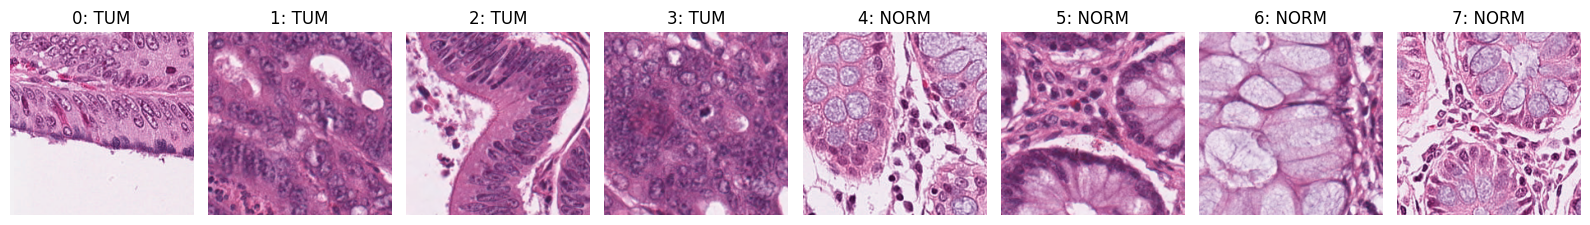

In [3]:
d = np.load(CACHE_NCT)
Xtr, ytr = d["Xtr"], d["ytr"]                 # solo TRAIN
print("TRAIN", Xtr.shape, Xtr.dtype, {c: int((ytr == c).sum()) for c in ["TUM", "NORM"]})

rng = np.random.default_rng(SEED)
idx_tum  = rng.choice(np.where(ytr == "TUM")[0],  size=4, replace=False)
idx_norm = rng.choice(np.where(ytr == "NORM")[0], size=4, replace=False)
idx_lote  = np.concatenate([idx_tum, idx_norm])   # posiciones 0–3 TUM, 4–7 NORM
etiquetas = ytr[idx_lote]

import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 8, figsize=(16, 2.6))
for k, (eje, i) in enumerate(zip(ejes, idx_lote)):
    eje.imshow(Xtr[i]); eje.set_title(f"{k}: {ytr[i]}"); eje.axis("off")
plt.tight_layout(); plt.show()

### **§2 ResNet-50 sin cabeza = extractor de rasgos**

---

Qué hace: carga ResNet-50 desde el archivo local, sin la capa final de 1000 clases de ImageNet (num_classes=0), en modo evaluación.
Puente: usar al observador experto solo para describir, no para dar su diagnóstico de «perro» o «coche».

In [6]:
modelo = timm.create_model(
    "resnet50.a1_in1k", pretrained=True, num_classes=0,
    pretrained_cfg_overlay=dict(file=str(ARCHIVO_PESOS)),   # offline: desde la caché
)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
modelo = modelo.to(dispositivo).eval()
print(f"Parámetros: {sum(p.numel() for p in modelo.parameters()) / 1e6:.1f} M"
      f" | rasgos por parche: {modelo.num_features}")

Parámetros: 23.5 M | rasgos por parche: 2048


### **§3 Embeddings del lote**

---

Qué hace: aplica el preprocesamiento de timm (caja negra hoy; se abre el Día 42), apila los 8 parches en un tensor y obtiene un vector por parche sin calcular gradientes.
Predicción antes de correr: forma del lote = ¿? · forma de la salida = ¿? · ¿habrá valores negativos?
Puente: de la imagen al informe sinóptico, pero con 2048 casillas que nadie nombró.

In [7]:
from PIL import Image

cfg = timm.data.resolve_data_config({}, model=modelo)
transform = timm.data.create_transform(**cfg)
print(cfg)                                     # fíjate en mean, std y crop_pct

lote = torch.stack([transform(Image.fromarray(Xtr[i])) for i in idx_lote]).to(dispositivo)
print("Lote de entrada:", tuple(lote.shape))

with torch.no_grad():
    emb = modelo(lote).cpu().numpy()
print("Embeddings:", emb.shape,
      f"| mínimo {emb.min():.3f} | máximo {emb.max():.3f} | % ceros {(emb == 0).mean():.1%}")

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.95, 'crop_mode': 'center'}
Lote de entrada: (8, 3, 224, 224)
Embeddings: (8, 2048) | mínimo 0.000 | máximo 2.684 | % ceros 42.6%


### **§4 ¿Qué parches «le parecen» iguales al modelo?**

---

Qué hace: normaliza cada vector a longitud 1 y calcula la similitud coseno entre todos los pares (8 × 8). Resume TUM–TUM, NORM–NORM y TUM–NORM.
Predicción: ¿qué es mayor, TUM–TUM o TUM–NORM?
Puente: comparar dos campos y decidir si son el mismo tejido.

ResNet-50 (2048)       TUM–TUM 0.543 | NORM–NORM 0.645 | TUM–NORM 0.551


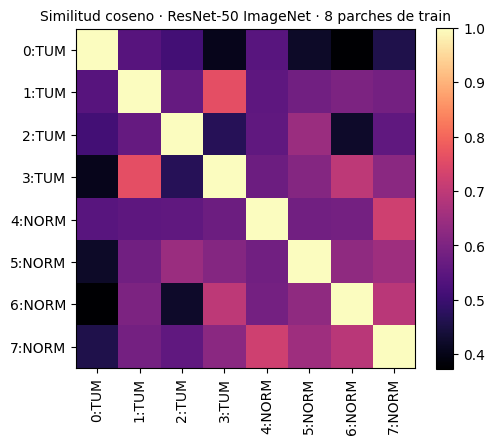

In [8]:
def matriz_coseno(F):
    """Similitud coseno entre las filas de F (n, p) → matriz (n, n)."""
    Fn = F / np.linalg.norm(F, axis=1, keepdims=True)
    return Fn @ Fn.T

def resumen_coseno(S, titulo):
    iu = np.triu_indices(4, k=1)                   # pares distintos dentro de cada clase
    print(f"{titulo:<22} TUM–TUM {S[:4, :4][iu].mean():.3f} | "
          f"NORM–NORM {S[4:, 4:][iu].mean():.3f} | TUM–NORM {S[:4, 4:].mean():.3f}")

def figura_coseno(S, titulo, archivo):
    nombres = [f"{k}:{e}" for k, e in enumerate(etiquetas)]
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    im = ax.imshow(S, cmap="magma"); plt.colorbar(im)
    ax.set_xticks(range(8), nombres, rotation=90); ax.set_yticks(range(8), nombres)
    ax.set_title(titulo, fontsize=10)
    plt.tight_layout(); plt.savefig(RESULTS / archivo, dpi=150); plt.show()

S_resnet = matriz_coseno(emb)
resumen_coseno(S_resnet, "ResNet-50 (2048)")
figura_coseno(S_resnet, "Similitud coseno · ResNet-50 ImageNet · 8 parches de train",
              "07_coseno_resnet50_lote8.png")

### **§5 Variante: la misma pregunta con los rasgos que tú elegiste**

---

Qué hace: recalcula las 6 features de color, añade las 5 de textura desde la caché, estandariza (escalador ajustado en train) y repite la matriz coseno.
Puente: la misma comparación con tu hoja de criterios en lugar del golpe de vista.

Features hechas a mano: (1200, 11)
Color + textura (11)   TUM–TUM 0.069 | NORM–NORM -0.090 | TUM–NORM -0.168
ResNet-50 (2048)       TUM–TUM 0.543 | NORM–NORM 0.645 | TUM–NORM 0.551


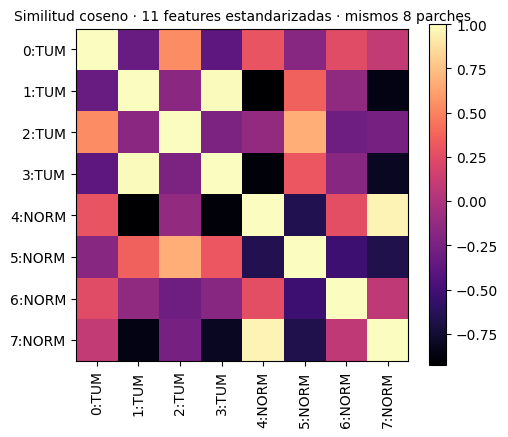

In [9]:
from sklearn.preprocessing import StandardScaler

def features_color(tile_rgb):
    """Media y DE por canal de un parche RGB (alto, ancho, 3) → vector (6,)."""
    return np.concatenate([tile_rgb.mean(axis=(0, 1)), tile_rgb.std(axis=(0, 1))])

Xtr_color = np.stack([features_color(t) for t in Xtr])
Xtr_tex   = np.load(CACHE_TEX)["Xtr_tex"]          # mismo orden que Xtr
X11_tr    = np.hstack([Xtr_color, Xtr_tex])
print("Features hechas a mano:", X11_tr.shape)

escala = StandardScaler().fit(X11_tr)              # ajustado en train (aquí no hay test)
S_11 = matriz_coseno(escala.transform(X11_tr[idx_lote]))
resumen_coseno(S_11, "Color + textura (11)")
resumen_coseno(S_resnet, "ResNet-50 (2048)")
figura_coseno(S_11, "Similitud coseno · 11 features estandarizadas · mismos 8 parches",
              "07_coseno_11feat_lote8.png")

In [10]:
print(np.round(S_11[:4, :4], 2))   # solo los 4 TUM: ¿0 y 2 siguen lejos de 1 y 3?

[[ 1.   -0.33  0.54 -0.38]
 [-0.33  1.   -0.17  0.99]
 [ 0.54 -0.17  1.   -0.23]
 [-0.38  0.99 -0.23  1.  ]]


# **E1 · Unidad de análisis**

---



### **E1 ⭐ Tipos de variables y unidad de análisis**

---

Qué hace: arma una tabla con cada variable que usas: tipo y nivel (paciente, laminilla, parche, análisis). Llénala tú; la celda solo te da el esqueleto.
Puente: paciente → bloque → laminilla → campo.

In [2]:
import pandas as pd

filas = [
    # variable            tipo                    nivel        nota
    ("slide_id",          "categórica nominal",   "laminilla", "identifica la laminilla (CMU-1)"),
    ("pct_tejido",        "numérica continua",    "parche",    "fracción 0–1 de tejido en el tile"),
    ("x",                 "discreta",             "parche",    "ancho del tile"),
    ("y",                 "discreta",             "parche",    "alto del tile"),
    ("nivel",             "discreta",             "parche",    "nivel de la piramide de WSI en que trabaja el parche"),
    ("w",                 "discrteta",            "parche",    "nivel en x donde se inicia el corte"),
    ("h",                 "discreta",             "parche",    "nivel en y donde inicia el corte"),
    ("MPP",               "continua",             "laminilla", "micras por pixel"),
    ("fuente",            "nominal",              "laminilla", "recurso donde se extrajo el WSI"),
    ("semilla",           "discreta",             "analisis",  "semilla asignada para reproducibilidad"),
    ("ytr (npz)",         "nominal",              "parche",    "¿a qué nivel se asignó REALMENTE? (TUM/NORM)"),
    ("embedding (2048)",  "continua?",            "parche",    "2048 variables (una por filtro)"),
    ("patient_id",        "nominal",              "paciente",  "NO existe en NCT-CRC por parche"),
]
e1 = pd.DataFrame(filas, columns=["variable", "tipo", "nivel", "nota"])
e1

,variable,tipo,nivel,nota
0,slide_id,categórica nominal,laminilla,identifica la laminilla (CMU-1)
1,pct_tejido,numérica continua,parche,fracción 0–1 de tejido en el tile
2,x,discreta,parche,ancho del tile
3,y,discreta,parche,alto del tile
4,nivel,discreta,parche,nivel de la piramide de WSI en que trabaja el ...
5,w,discrteta,parche,nivel en x donde se inicia el corte
6,h,discreta,parche,nivel en y donde inicia el corte
7,MPP,continua,laminilla,micras por pixel
8,fuente,nominal,laminilla,recurso donde se extrajo el WSI
9,semilla,discreta,analisis,semilla asignada para reproducibilidad
